In [37]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import confusion_matrix, classification_report,f1_score,precision_score,recall_score


In [22]:
df = pd.read_csv('creditcard.csv')
df = df.drop_duplicates()

df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Logistic Regression = Probability - based baseline; 
### Decision Tree = learned sequences of splits; 
### Random Forest = ensemble/collection of decision trees;

In [23]:
X = df.drop(columns= ['Class'])
y = df['Class']


### Train Test split: 
Why we are splitting the dataset into training and testing sets?
- We split the dataset into training and testing sets to evaluate the performance of our machine learning model. The training set is used to train the model, allowing it to learn patterns and relationships in the data. The testing set, on the other hand, is used to assess how well the model generalizes to new, unseen data. This helps us identify issues like overfitting, where the model performs well on the training data but poorly on the testing data. By using a separate testing set, we can get a more accurate measure of the model's predictive performance and ensure that it will work effectively in real-world scenarios.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42,stratify=y)

print("Training shape: ", X_train.shape)

Training shape:  (226980, 30)


In [25]:
print("Test Data: ", X_test.shape)

Test Data:  (56746, 30)


In [26]:
print("Fraud rate in training data: ",y_train.mean())
print("Fraud rate in test data: ", y_test.mean())

Fraud rate in training data:  0.0016653449643140364
Fraud rate in test data:  0.0016741268107003137


#### Why Random split without stratification is not a good idea?
- Randomly splitting the dataset without stratification can lead to an imbalanced distribution of classes in the training and testing sets, especially in cases where the dataset is imbalanced (i.e., one class is significantly more prevalent than the other). This can result in a training set that does not adequately represent the minority class, leading to poor model performance and biased predictions. Stratified splitting ensures that the class distribution is preserved in both the training and testing sets, allowing the model to learn from a representative sample of the data and improving its ability to generalize to unseen instances.

In [27]:
model = Pipeline(steps=[
                        ('scaler',StandardScaler()),
                        ('classifier',LogisticRegression(max_iter=100))
                        ])


In [28]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [29]:
y_pred = model.predict(X_test)

Tree Model : |

In [30]:
from sklearn.tree import DecisionTreeClassifier 

tree_model = DecisionTreeClassifier(
max_depth=4,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(X_train,y_train)
tree_pred = tree_model.predict(X_test)
print(confusion_matrix(y_test,tree_pred))
print(classification_report(y_test,tree_pred,digits=4))

[[54538  2113]
 [   15    80]]
              precision    recall  f1-score   support

           0     0.9997    0.9627    0.9809     56651
           1     0.0365    0.8421    0.0699        95

    accuracy                         0.9625     56746
   macro avg     0.5181    0.9024    0.5254     56746
weighted avg     0.9981    0.9625    0.9793     56746



In [31]:
for depth in [2,4,6,8 ,10, None] : 
    candidate = DecisionTreeClassifier(
            max_depth = depth, min_samples_leaf = 10,
            class_weight="balanced",
            random_state=42
    )

    candidate.fit(X_train,y_train)
    train_pred = candidate.predict(X_train)
    test_pred = candidate.predict(X_test)

    print(depth,f1_score(y_train,train_pred, zero_division=0),
          f1_score(y_test, test_pred, zero_division = 0) )

2 0.12092515024585686 0.11078717201166181
4 0.07788534754704667 0.06993006993006994
6 0.14181678804139516 0.12569610182975338
8 0.27798369162342473 0.23565891472868217
10 0.4244806288601909 0.3619047619047619
None 0.769857433808554 0.5645161290322581


In [32]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

### Random Forest : 
Ensemble of decision trees. 


In [33]:
from sklearn.ensemble import RandomForestClassifier 

rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs = -1,
    random_state=42
)

In [54]:
rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)

# print("Confusion Matrix: ",confusion_matrix(y_test,rf_pred))
# print("Classification report: ", classification_report(y_test,rf_pred,digits=4))
# rf_model.save("rf_Model_fraud.h5")

In [ ]:
print(rf_model.classes_)
probabilities = rf_model.predict_proba(X_test)
fraud_col = list(rf_model.classes_).index(1)
fraud_probability = probabilities[:,fraud_col]
print(fraud_probability[:10])

[0 1]
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.005      0.
 0.         0.         0.         0.         0.         0.
 0.005      0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.0049917  0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.00498355 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.   

In [44]:
for threshold in [0.5,0.3,0.1]: 
    pred = (fraud_probability >= threshold).astype(int)
    print("\nThreshold: ", threshold)
    print(confusion_matrix(y_test,pred))
    print("Classification report: ",classification_report(y_test, pred,digits=4,zero_division=0))


Threshold:  0.5
[[56648     3]
 [   26    69]]
Classification report:                precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     56651
           1     0.9583    0.7263    0.8263        95

    accuracy                         0.9995     56746
   macro avg     0.9789    0.8631    0.9130     56746
weighted avg     0.9995    0.9995    0.9995     56746


Threshold:  0.3
[[56646     5]
 [   23    72]]
Classification report:                precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56651
           1     0.9351    0.7579    0.8372        95

    accuracy                         0.9995     56746
   macro avg     0.9673    0.8789    0.9185     56746
weighted avg     0.9995    0.9995    0.9995     56746


Threshold:  0.1
[[56634    17]
 [   19    76]]
Classification report:                precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     56651
           1     0.81

## Threshold Comparison table:

In [46]:
rows = []
thr = [0.5,0.4, 0.3,0.2,0.1,0.05]
for threshold in thr: 
    pred = (fraud_probability >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test,pred,zero_division=0),
        "recall": recall_score(y_test,pred,zero_division=0),
        "f1": f1_score(y_test,pred,zero_division=0),
        "alerts": int(pred.sum())
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results)

,threshold,precision,recall,f1,alerts
0,0.50,0.958333,0.726316,0.826347,72
1,0.40,0.945946,0.736842,0.828402,74
2,0.30,0.935065,0.757895,0.837209,77
3,0.20,0.924051,0.768421,0.839080,79
4,0.10,0.817204,0.800000,0.808511,93
5,0.05,0.666667,0.821053,0.735849,117


In [47]:
cm = confusion_matrix(y_test,pred, labels=[0,1])
tn,fp,fn,tp = cm.ravel()
precision = tp/(tp+fp) if tp+fp else 0 
recall = tp/ (tp+fn) if tp+fn else 0 
fpr = fp / (fp+tn) if fp+tn else 0 
print("Precision: ",precision)
print("Recall: ", recall)
print("False Positive Rate : ",fpr)

Precision:  0.6666666666666666
Recall:  0.8210526315789474
False Positive Rate :  0.0006884256235547474


### ROC curve and ROC AUC

AttributeError: 'RandomForestClassifier' object has no attribute 'save'

In [48]:
import matplotlib.pyplot as plt 
from sklearn.metrics import roc_curve, roc_auc_score

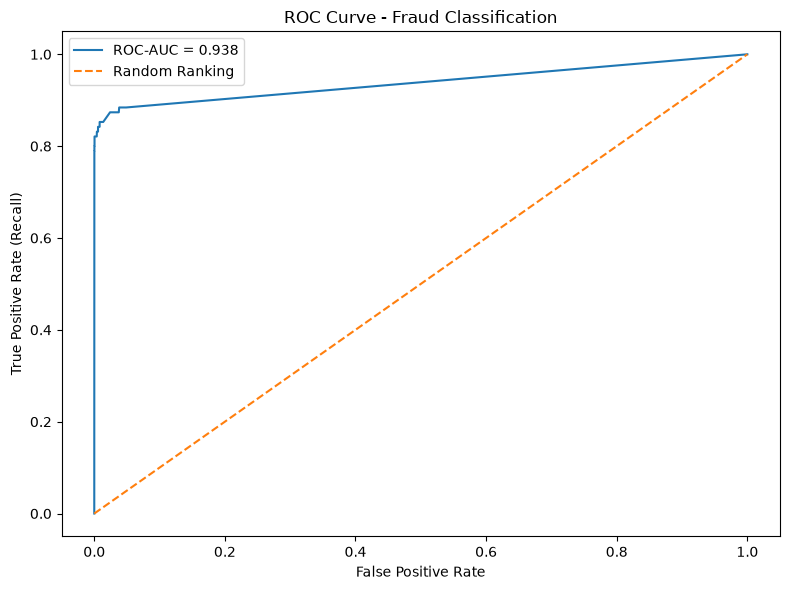

In [49]:
fpr_values,tpr_values,roc_thresholds = roc_curve(y_test,fraud_probability)
roc_auc = roc_auc_score(y_test,fraud_probability)

plt.figure(figsize=(8,6))
plt.plot(fpr_values,tpr_values, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'--',label="Random Ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Fraud Classification")
plt.legend()
plt.tight_layout()
plt.show()


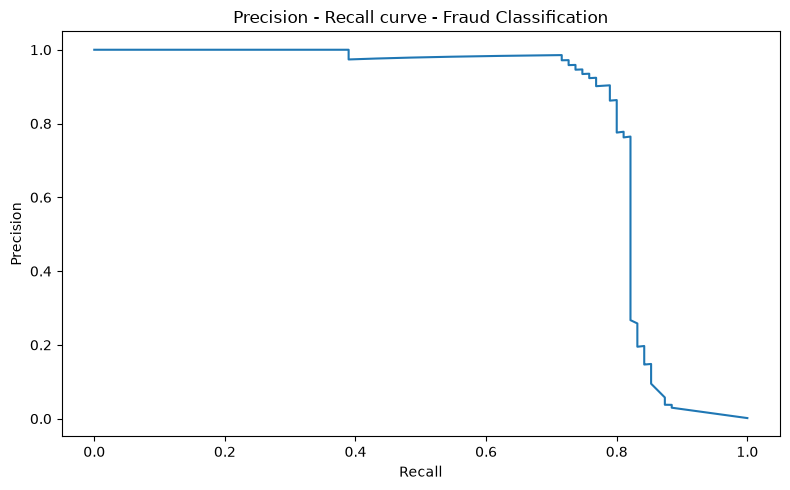

In [50]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test,fraud_probability)
ap = average_precision_score(y_test,fraud_probability)

plt.figure(figsize=(8,5))

plt.plot(pr_recall,pr_precision,label=f"Average Precision = {ap:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision - Recall curve - Fraud Classification")
plt.tight_layout()
plt.show()

### Compare 3 models : 

In [38]:
predictions = { 
    "Logistic Regression": y_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred
    
}

for name, pred in predictions.items(): 
    print(name,"Precision: ",precision_score(y_test,y_pred,zero_division=0),
          "Recall: ",recall_score(y_test,pred,zero_division=0),
          "F1: ",f1_score(y_test,y_pred,zero_division=0)
    )


Logistic Regression Precision:  0.8461538461538461 Recall:  0.5789473684210527 F1:  0.6875
Decision Tree Precision:  0.8461538461538461 Recall:  0.8421052631578947 F1:  0.6875
Random Forest Precision:  0.8461538461538461 Recall:  0.7263157894736842 F1:  0.6875


### Evaluation Metrics: 
Confusion matrix compares actual labels with predicted labels. 
- True Positive (TP): The number of instances that were correctly predicted as positive (fraudulent transactions).
- True Negative (TN): The number of instances that were correctly predicted as negative (non-fraudulent transactions).
- False Positive (FP): The number of instances that were incorrectly predicted as positive (non-fraudulent transactions).
- False Negative (FN): The number of instances that were incorrectly predicted as negative (fraudulent transactions).

In [ ]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[56641    10]
 [   40    55]]


In [ ]:
print(classification_report(y_test,y_pred,digits=4))

              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8462    0.5789    0.6875        95

    accuracy                         0.9991     56746
   macro avg     0.9227    0.7894    0.8435     56746
weighted avg     0.9990    0.9991    0.9990     56746



#### Precision: 
-  Precision is the ratio of correctly predicted positive observations to the total predicted positive observations. It is calculated as:-

Precision = $\frac{TP}{TP + FP}$

#### Recall 
- Recall (also known as Sensitivity or True Positive Rate) is the ratio of correctly predicted positive observations to all the actual positive observations. It is calculated as:-

Recall = $\frac{TP}{TP + FN}$

#### F1 Score
- F1 Score is the weighted average of Precision and Recall. It is calculated as:-

F1 Score = 2 * $\frac{Precision * Recall}{Precision + Recall}$
  

In [ ]:
len(y_test[y_test==0])

56651

In [ ]:
fraud_probability = model.predict_proba(X_test)[:, 1]
custom_threshold = 0.20

y_pred_020 = (fraud_probability >= custom_threshold).astype(int)

print(classification_report(y_test,y_pred_020,digits=4))

[0 0 0 ... 0 0 0]
              precision    recall  f1-score   support

           0     0.9995    0.9998    0.9996     56651
           1     0.8333    0.6842    0.7514        95

    accuracy                         0.9992     56746
   macro avg     0.9164    0.8420    0.8755     56746
weighted avg     0.9992    0.9992    0.9992     56746

